# Setup

In [ ]:
# imports
import pandas as pd
import os
import copy
import warnings
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from scipy import stats

In [ ]:
# Configurations of experiment settings

SEEDS = [0] # 5 test scores per condition
N_FOLDS = 5 # stratified k-fold
VAL_FRAC = 0.20 # fraction of training folds out for early stopping
HIDDEN = (32, 16) # hidden layer widths (m1, m2)
BATCH_SIZE = 32
LR = 1e-3 # Adam learning rate
MAX_EPOCHS = 300 # large because small n so less weight updates putting computational strain
MIN_EPOCHS = 20
PATIENCE = 20 # Early stopping regularization

COST_FN = 20 # cost of false negative (predicted survival when death event)
COST_FP = 1  # cost of false positive
COST_RATIOS = [5, 10, 20] # cost of false negative to cost of false positive ratios
TAU_GRID = np.round(np.arange(0.01, 0.951, 0.01), 2)

L2_GRID = [1e-3, 1e-2, 1e-1] # experiment 3: lambda values in J = BCE + (lambda/2) * ||W||^2
DROPOUT_GRID = [0.2, 0.5] # experiment 3: dropout probability p

RESULTS_DIR = "results"
os.makedirs(RESULTS_DIR, exist_ok=True)



```
```

# Data


In [ ]:
# Install the required package if missing
!pip install -q ucimlrepo

# Load the dataset
def load_data():
  try:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=519)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    src = "UCI repository(id 519)"
    print("Loaded from", src, "| shape ", df.shape, "| head ", df.head())
    return df
  except Exception as e:
    print("Data download failed:", e)
    return None

df = load_data()


Loaded from UCI repository(id 519) | shape  (299, 13) | head  <bound method NDFrame.head of       age  anaemia  creatinine_phosphokinase  diabetes  ejection_fraction  \
0    75.0        0                       582         0                 20   
1    55.0        0                      7861         0                 38   
2    65.0        0                       146         0                 20   
3    50.0        1                       111         0                 20   
4    65.0        1                       160         1                 20   
..    ...      ...                       ...       ...                ...   
294  62.0        0                        61         1                 38   
295  55.0        0                      1820         0                 38   
296  45.0        0                      2060         1                 60   
297  45.0        0                      2413         0                 38   
298  50.0        0                       196         0       

In [ ]:
# set features
# drop time because it is affected by if a person dies.
import numpy as np

TARGET = "death_event"
CONT = ["age", "creatinine_phosphokinase", "ejection_fraction", "platelets", "serum_creatinine", "serum_sodium"]
BINARY = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"]
FEATURES = CONT + BINARY

missing = [c for c in FEATURES + [TARGET] if c not in df.columns]
assert not missing, f"Missing columns: {missing}"
df = df[FEATURES + [TARGET]].copy()
y_all = df[TARGET].to_numpy().astype(np.float32)


print(f"Patients {len(df)} | deaths: {int(y_all.sum())} ({y_all.mean():.1%}) | features used {len(FEATURES)}")

Patients 299 | deaths: 96 (32.1%) | features used 11


In [ ]:
# data problems

# Class imbalance
print("Class balance: ", dict(df[TARGET].value_counts()))

print("Missing values: ", dict(df.isna().sum()))
print("Duplicate rows: ", df.duplicated().sum())
print("Duplicate columns: ", df.columns.duplicated().sum())

# Missing continuous values imputed with the mean:
print("duplicate age:", (df["age"] == 60.83).sum())
print("duplicate creatinine_phosphokinase:", (df["creatinine_phosphokinase"] == 581.84).sum())
print("duplicate ejection_fraction:", (df["ejection_fraction"] == 38.08).sum())
print("duplicate serum_creatinine:", (df["serum_creatinine"] == 1.39).sum())
print("duplicate platelets:", (df["platelets"] == 263358.03).sum())
print("duplicate serum_sodium:", (df["serum_sodium"] == 136.63).sum())
for c in CONT:
    s = df[c]
    print(f"{c:26s} rows ≈ mean: {np.isclose(s, s.mean(), atol=0.01).sum():3d}   non-integer: {(s % 1 != 0).sum()}")

# small-n overfitting
print(f"Always predicting 'survived' would score {1 - y_all.mean():.1%} accuracy.\n")

# need for standardization
df[CONT].describe().T[["mean", "std", "min", "max"]].round(2)

Class balance:  {0: np.int64(203), 1: np.int64(96)}
Missing values:  {'age': np.int64(0), 'creatinine_phosphokinase': np.int64(0), 'ejection_fraction': np.int64(0), 'platelets': np.int64(0), 'serum_creatinine': np.int64(0), 'serum_sodium': np.int64(0), 'anaemia': np.int64(0), 'diabetes': np.int64(0), 'high_blood_pressure': np.int64(0), 'sex': np.int64(0), 'smoking': np.int64(0), 'death_event': np.int64(0)}
Duplicate rows:  0
Duplicate columns:  0
duplicate age: 0
duplicate creatinine_phosphokinase: 0
duplicate ejection_fraction: 0
duplicate serum_creatinine: 0
duplicate platelets: 25
duplicate serum_sodium: 0
age                        rows ≈ mean:   0   non-integer: 2
creatinine_phosphokinase   rows ≈ mean:   0   non-integer: 0
ejection_fraction          rows ≈ mean:   0   non-integer: 0
platelets                  rows ≈ mean:  25   non-integer: 25
serum_creatinine           rows ≈ mean:   9   non-integer: 243
serum_sodium               rows ≈ mean:   0   non-integer: 0
Always predict

,mean,std,min,max
age,60.83,11.89,40.0,95.0
creatinine_phosphokinase,581.84,970.29,23.0,7861.0
ejection_fraction,38.08,11.83,14.0,80.0
platelets,263358.03,97804.24,25100.0,850000.0
serum_creatinine,1.39,1.03,0.5,9.4
serum_sodium,136.63,4.41,113.0,148.0


# Base Model

In [ ]:
def make_model(dropout=0.0):
    layers, d_in = [], len(FEATURES)
    for width in HIDDEN:
        layers += [nn.Linear(d_in, width), nn.ReLU()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        d_in = width

    # one logit s; p_hat = sigmoid(s)
    layers.append(nn.Linear(d_in, 1))
    return nn.Sequential(*layers)

def preprocess(train_df, other_dfs, standardize=True):
    # Fit the scaler on the training rows only, then apply it to validation/test rows (no leakage).
    outs = [d[FEATURES].copy() for d in [train_df, *other_dfs]]
    if standardize:
        scaler = StandardScaler().fit(train_df[CONT])
        for o in outs:
            o[CONT] = scaler.transform(o[CONT])
    return [o.to_numpy(np.float32) for o in outs]

def oversample(X, y, rng):
    # Randomly duplicate deaths (with replacement) until both classes are the same size.
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    extra = rng.choice(pos, size=len(neg) - len(pos), replace=True)
    idx = np.concatenate([neg, pos, extra]); rng.shuffle(idx)
    return X[idx], y[idx]

def l2_penalty(model):
    # sum of squared weights (biases excluded), as in J = R_hat + (lambda/2)||W||^2
    return sum((p ** 2).sum() for name, p in model.named_parameters() if p.dim() > 1)

def predict_proba(model, X):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(X)).squeeze(1)).numpy()

In [ ]:
def train_model(Xtr, ytr, Xva, yva, l2=0.0, dropout=0.0, early_stopping=True, seed=0):
    torch.manual_seed(seed)
    model = make_model(dropout)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    bce = nn.BCEWithLogitsLoss()

    Xtr_t, ytr_t = torch.from_numpy(Xtr), torch.from_numpy(ytr)
    Xva_t, yva_t = torch.from_numpy(Xva), torch.from_numpy(yva)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"train": [], "val": []}
    best_val, best_state, best_epoch, wait = np.inf, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()                                   # dropout active
        for xb, yb in loader:
            opt.zero_grad()
            loss = bce(model(xb).squeeze(1), yb)        # forward pass + BCE
            if l2 > 0:
                loss = loss + (l2 / 2) * l2_penalty(model)
            loss.backward()                             # backprop: gradients
            opt.step()                                  # Adam: update weights

        model.eval()                                    # dropout off; log data loss only (no penalty)
        with torch.no_grad():
            tr = bce(model(Xtr_t).squeeze(1), ytr_t).item()
            va = bce(model(Xva_t).squeeze(1), yva_t).item()
        hist["train"].append(tr); hist["val"].append(va)

        if va < best_val - 1e-6:
            best_val, best_state, best_epoch, wait = va, copy.deepcopy(model.state_dict()), epoch, 0
        else:
            wait += 1
        if early_stopping and epoch >= MIN_EPOCHS and wait >= PATIENCE:
            break

    used_epoch = len(hist["val"])
    if early_stopping:                                  # restore the best epoch's weights
        model.load_state_dict(best_state); used_epoch = best_epoch
    return model, hist, best_epoch, used_epoch

In [ ]:
def threshold_metrics(y, p, tau, c_fn=COST_FN, c_fp=COST_FP):
    pred = (p >= tau).astype(int); y = y.astype(int)
    tp = int(((pred == 1) & (y == 1)).sum()); fn = int(((pred == 0) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum()); tn = int(((pred == 0) & (y == 0)).sum())
    recall    = tp / (tp + fn) if tp + fn else np.nan
    precision = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * precision * recall / (precision + recall) if (tp and precision + recall) else 0.0
    return dict(recall=recall, precision=precision, f1=f1, specificity=tn / (tn + fp) if tn + fp else np.nan,
                accuracy=(tp + tn) / len(y), TP=tp, FN=fn, FP=fp, TN=tn, cost=(c_fn * fn + c_fp * fp) / len(y))

def prob_metrics(y, p):
    return dict(auc=roc_auc_score(y, p), pr_auc=average_precision_score(y, p),
                brier=brier_score_loss(y, p), test_bce=log_loss(y, np.clip(p, 1e-7, 1 - 1e-7)))

In [ ]:
def run_cv(name, standardize=True, oversample_train=False, l2=0.0, dropout=0.0, early_stopping=True):
    rows, preds = [], []
    for seed in SEEDS:
        skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        for fold, (trval_idx, te_idx) in enumerate(skf.split(df, y_all)):
            run_seed = seed * 100 + fold
            tr_idx, va_idx = train_test_split(trval_idx, test_size=VAL_FRAC,
                                              stratify=y_all[trval_idx], random_state=run_seed)
            Xtr, Xva, Xte = preprocess(df.iloc[tr_idx], [df.iloc[va_idx], df.iloc[te_idx]], standardize)
            ytr, yva, yte = y_all[tr_idx], y_all[va_idx], y_all[te_idx]
            if oversample_train:                       # training rows only, never validation/test
                Xtr, ytr = oversample(Xtr, ytr, np.random.default_rng(run_seed))

            model, hist, best_epoch, used_epoch = train_model(Xtr, ytr, Xva, yva, l2=l2, dropout=dropout,
                                                              early_stopping=early_stopping, seed=run_seed)
            p_va, p_te = predict_proba(model, Xva), predict_proba(model, Xte)

            tr_loss, va_loss = hist["train"][used_epoch - 1], hist["val"][used_epoch - 1]
            rows.append(dict(condition=name, seed=seed, fold=fold, n_train=len(tr_idx), n_val=len(va_idx),
                             n_test=len(te_idx), epochs_run=len(hist["val"]), best_epoch=best_epoch,
                             train_loss=tr_loss, val_loss=va_loss, gap=va_loss - tr_loss,
                             **prob_metrics(yte, p_te), **threshold_metrics(yte, p_te, 0.5)))
            preds.append(dict(condition=name, seed=seed, fold=fold, test_idx=te_idx, y_val=yva, p_val=p_va,
                              y_test=yte, p_test=p_te, hist=hist))
    print(f"{name}: {len(rows)} runs done")
    return pd.DataFrame(rows), preds

In [ ]:
def mean_std(table, cols, by="condition"):
    # One row per condition, each cell "mean ± std" over folds (sample std, ddof=1)
    g = table.groupby(by, sort=False)[cols]
    m, s = g.mean(), g.std(ddof=1)
    out = pd.DataFrame(index=m.index)
    for c in cols:
        out[c] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(m[c], s[c])]
    return out

def paired(table, cond_a, cond_b, metric, by="condition"):
    # Fold-by-fold difference (b − a) on identical splits, plus a paired t-test
    a = table[table[by] == cond_a].sort_values(["seed", "fold"])[metric].to_numpy(float)
    b = table[table[by] == cond_b].sort_values(["seed", "fold"])[metric].to_numpy(float)
    d = b - a
    p = stats.ttest_rel(b, a).pvalue if len(d) > 1 and d.std() > 0 else np.nan
    return dict(metric=metric, comparison=f"{cond_b} − {cond_a}", mean_diff=round(d.mean(), 4),
                std_diff=round(d.std(ddof=1), 4) if len(d) > 1 else np.nan,
                folds_higher=f"{(d > 0).sum()}/{len(d)}", p_value=round(p, 4) if p == p else np.nan)

# Experiment 1
1. class imbalance: baseline vs. oversampled training data

In [ ]:
res_base, preds_base = run_cv("baseline")
res_over, preds_over = run_cv("oversampled", oversample_train=True)
exp1 = pd.concat([res_base, res_over], ignore_index=True)

EXP1_COLS = ["recall", "precision", "f1", "specificity", "auc", "pr_auc"]
display(mean_std(exp1, EXP1_COLS))
display(pd.DataFrame([paired(exp1, "baseline", "oversampled", m) for m in ["recall", "precision", "f1", "auc"]]))

baseline: 5 runs done
oversampled: 5 runs done


,recall,precision,f1,specificity,auc,pr_auc
condition,,,,,,
baseline,0.438 ± 0.092,0.635 ± 0.169,0.506 ± 0.081,0.862 ± 0.091,0.749 ± 0.081,0.618 ± 0.145
oversampled,0.686 ± 0.136,0.613 ± 0.155,0.639 ± 0.121,0.778 ± 0.127,0.768 ± 0.072,0.628 ± 0.159


,metric,comparison,mean_diff,std_diff,folds_higher,p_value
0,recall,oversampled − baseline,0.2479,0.1689,5/5,0.0304
1,precision,oversampled − baseline,-0.0217,0.0553,1/5,0.4298
2,f1,oversampled − baseline,0.1328,0.1203,5/5,0.0692
3,auc,oversampled − baseline,0.0181,0.0219,4/5,0.1383


# Experiment 2
2. cost-minimization: minimize decision threshold

In [ ]:
def tune_tau(y, p, c_fn, c_fp):
    costs = [threshold_metrics(y, p, t, c_fn, c_fp)["cost"] for t in TAU_GRID]
    return float(TAU_GRID[int(np.argmin(costs))])

exp2_rows = []
for ratio in COST_RATIOS:
    c_fn, c_fp = ratio, 1
    tau_star = c_fp / (c_fp + c_fn)
    for r in preds_base:
        tau_hat = tune_tau(r["y_val"], r["p_val"], c_fn, c_fp)
        policies = {"default 0.5": 0.5, "tuned τ̂*": tau_hat, "theoretical τ*": tau_star, "flag everyone": 0.0}
        for policy, tau in policies.items():
            m = threshold_metrics(r["y_test"], r["p_test"], tau, c_fn, c_fp)
            exp2_rows.append(dict(cost_ratio=ratio, policy=policy, tau=tau, seed=r["seed"], fold=r["fold"], **m))
exp2 = pd.DataFrame(exp2_rows)

main = exp2[exp2.cost_ratio == COST_FN]
print(f"Main result, cost ratio {COST_FN}:1 (test folds)")
display(mean_std(main, ["cost", "recall", "FP", "FN", "tau"], by="policy"))
display(pd.DataFrame([paired(main, "default 0.5", "tuned τ̂*", "cost", by="policy"),
                      paired(main, "flag everyone", "tuned τ̂*", "cost", by="policy"),
                      paired(main, "theoretical τ*", "tuned τ̂*", "cost", by="policy")]))

Main result, cost ratio 20:1 (test folds)


,cost,recall,FP,FN,tau
policy,,,,,
default 0.5,3.706 ± 0.624,0.438 ± 0.092,5.600 ± 3.715,10.800 ± 1.924,0.500 ± 0.000
tuned τ̂*,1.293 ± 0.552,0.863 ± 0.109,25.400 ± 9.343,2.600 ± 2.074,0.146 ± 0.065
theoretical τ*,0.722 ± 0.144,0.979 ± 0.029,35.200 ± 3.114,0.400 ± 0.548,0.048 ± 0.000
flag everyone,0.679 ± 0.007,1.000 ± 0.000,40.600 ± 0.548,0.000 ± 0.000,0.000 ± 0.000


,metric,comparison,mean_diff,std_diff,folds_higher,p_value
0,cost,tuned τ̂* − default 0.5,-2.4131,0.9630,0/5,0.0050
1,cost,tuned τ̂* − flag everyone,0.6142,0.5453,4/5,0.0655
2,cost,tuned τ̂* − theoretical τ*,0.5709,0.4498,4/5,0.0469


,mean,std,theoretical τ*
cost_ratio,,,
5,0.254,0.110,0.167
10,0.146,0.065,0.091
20,0.146,0.065,0.048


,cost,recall,FP
group,,,
5:1 default 0.5,0.997 ± 0.151,0.438 ± 0.092,5.600 ± 3.715
5:1 tuned τ̂*,0.666 ± 0.111,0.740 ± 0.081,14.800 ± 7.328
10:1 default 0.5,1.900 ± 0.305,0.438 ± 0.092,5.600 ± 3.715
10:1 tuned τ̂*,0.859 ± 0.213,0.863 ± 0.109,25.400 ± 9.343
20:1 default 0.5,3.706 ± 0.624,0.438 ± 0.092,5.600 ± 3.715
20:1 tuned τ̂*,1.293 ± 0.552,0.863 ± 0.109,25.400 ± 9.343


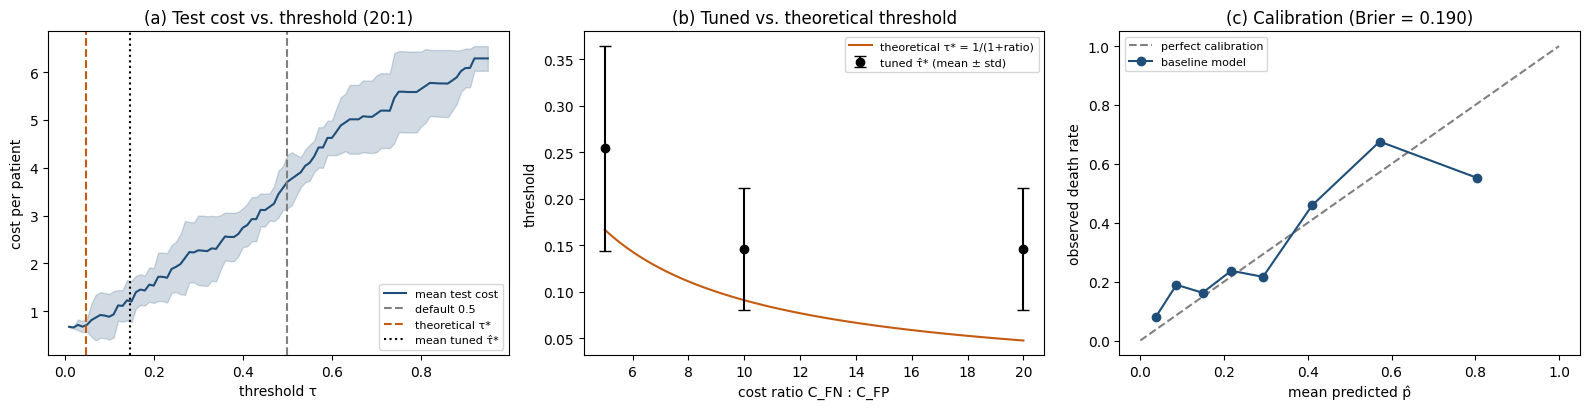

In [ ]:
# Sensitivity: does the tuned threshold track the theoretical one as the cost ratio changes?
tuned = exp2[exp2.policy == "tuned τ̂*"].groupby("cost_ratio")["tau"].agg(["mean", "std"])
tuned["theoretical τ*"] = [1 / (1 + r) for r in tuned.index]
display(tuned.round(3))
display(mean_std(exp2[exp2.policy.isin(["default 0.5", "tuned τ̂*"])].assign(
    group=lambda d: d.cost_ratio.astype(str) + ":1  " + d.policy), ["cost", "recall", "FP"], by="group"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# (a) test cost vs threshold, averaged over folds, at the main cost ratio
curves = np.array([[threshold_metrics(r["y_test"], r["p_test"], t)["cost"] for t in TAU_GRID] for r in preds_base])
ax = axes[0]
ax.plot(TAU_GRID, curves.mean(0), color="#1f4e79", label="mean test cost")
ax.fill_between(TAU_GRID, curves.mean(0) - curves.std(0), curves.mean(0) + curves.std(0), alpha=0.2, color="#1f4e79")
ax.axvline(0.5, ls="--", color="gray", label="default 0.5")
ax.axvline(COST_FP / (COST_FP + COST_FN), ls="--", color="#c55a11", label="theoretical τ*")
ax.axvline(main[main.policy == "tuned τ̂*"].tau.mean(), ls=":", color="black", label="mean tuned τ̂*")
ax.set(xlabel="threshold τ", ylabel="cost per patient", title=f"(a) Test cost vs. threshold ({COST_FN}:1)")
ax.legend(fontsize=8)

# (b) tuned vs theoretical threshold across cost ratios
ax = axes[1]
rr = np.linspace(min(COST_RATIOS), max(COST_RATIOS), 100)
ax.plot(rr, 1 / (1 + rr), color="#c55a11", label="theoretical τ* = 1/(1+ratio)")
ax.errorbar(tuned.index, tuned["mean"], yerr=tuned["std"], fmt="o", color="black", capsize=4, label="tuned τ̂* (mean ± std)")
ax.set(xlabel="cost ratio C_FN : C_FP", ylabel="threshold", title="(b) Tuned vs. theoretical threshold")
ax.legend(fontsize=8)

# (c) reliability diagram: are the probabilities calibrated? (pooled out-of-fold test predictions)
y_pool = np.concatenate([r["y_test"] for r in preds_base]); p_pool = np.concatenate([r["p_test"] for r in preds_base])
frac_pos, mean_pred = calibration_curve(y_pool, p_pool, n_bins=8, strategy="quantile")
ax = axes[2]
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="perfect calibration")
ax.plot(mean_pred, frac_pos, "o-", color="#1f4e79", label="baseline model")
ax.set(xlabel="mean predicted p̂", ylabel="observed death rate",
       title=f"(c) Calibration (Brier = {brier_score_loss(y_pool, p_pool):.3f})")
ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/exp2_threshold.png", dpi=200); plt.show()

# Experiment 3
3. overfitting: baseline regularization vs. L2 vs. dropout

In [ ]:
exp3_parts = [run_cv("none", early_stopping=False)[0]]
for lam in L2_GRID:
    exp3_parts.append(run_cv(f"L2 λ={lam:g}", l2=lam, early_stopping=False)[0])
for p in DROPOUT_GRID:
    exp3_parts.append(run_cv(f"dropout p={p}", dropout=p, early_stopping=False)[0])
exp3 = pd.concat(exp3_parts, ignore_index=True)

display(mean_std(exp3, ["train_loss", "val_loss", "gap", "test_bce", "auc", "recall"]))
display(pd.DataFrame([paired(exp3, "none", c, "gap") for c in exp3.condition.unique()[1:]] +
                     [paired(exp3, "none", c, "test_bce") for c in exp3.condition.unique()[1:]]))

none: 5 runs done
L2 λ=0.001: 5 runs done
L2 λ=0.01: 5 runs done
L2 λ=0.1: 5 runs done
dropout p=0.2: 5 runs done
dropout p=0.5: 5 runs done


,train_loss,val_loss,gap,test_bce,auc,recall
condition,,,,,,
none,0.056 ± 0.013,1.173 ± 0.421,1.117 ± 0.429,1.335 ± 0.416,0.675 ± 0.065,0.469 ± 0.058
L2 λ=0.001,0.071 ± 0.022,1.006 ± 0.375,0.934 ± 0.393,1.128 ± 0.357,0.705 ± 0.063,0.491 ± 0.076
L2 λ=0.01,0.240 ± 0.044,0.586 ± 0.170,0.346 ± 0.210,0.690 ± 0.156,0.724 ± 0.073,0.438 ± 0.063
L2 λ=0.1,0.585 ± 0.039,0.581 ± 0.029,-0.004 ± 0.013,0.593 ± 0.019,0.778 ± 0.084,0.042 ± 0.094
dropout p=0.2,0.184 ± 0.027,0.618 ± 0.177,0.434 ± 0.202,0.791 ± 0.297,0.732 ± 0.084,0.489 ± 0.058
dropout p=0.5,0.322 ± 0.029,0.509 ± 0.083,0.187 ± 0.099,0.621 ± 0.167,0.752 ± 0.077,0.478 ± 0.073


,metric,comparison,mean_diff,std_diff,folds_higher,p_value
0,gap,L2 λ=0.001 − none,-0.1825,0.0663,0/5,0.0035
1,gap,L2 λ=0.01 − none,-0.7711,0.2468,0/5,0.0022
2,gap,L2 λ=0.1 − none,-1.1204,0.4280,0/5,0.0042
3,gap,dropout p=0.2 − none,-0.6829,0.2483,0/5,0.0035
4,gap,dropout p=0.5 − none,-0.9297,0.3391,0/5,0.0036
5,test_bce,L2 λ=0.001 − none,-0.2064,0.1472,0/5,0.0350
6,test_bce,L2 λ=0.01 − none,-0.6447,0.2701,0/5,0.0059
7,test_bce,L2 λ=0.1 − none,-0.7412,0.4066,0/5,0.0151
8,test_bce,dropout p=0.2 − none,-0.5434,0.2486,0/5,0.0081
9,test_bce,dropout p=0.5 − none,-0.7133,0.3143,0/5,0.0071


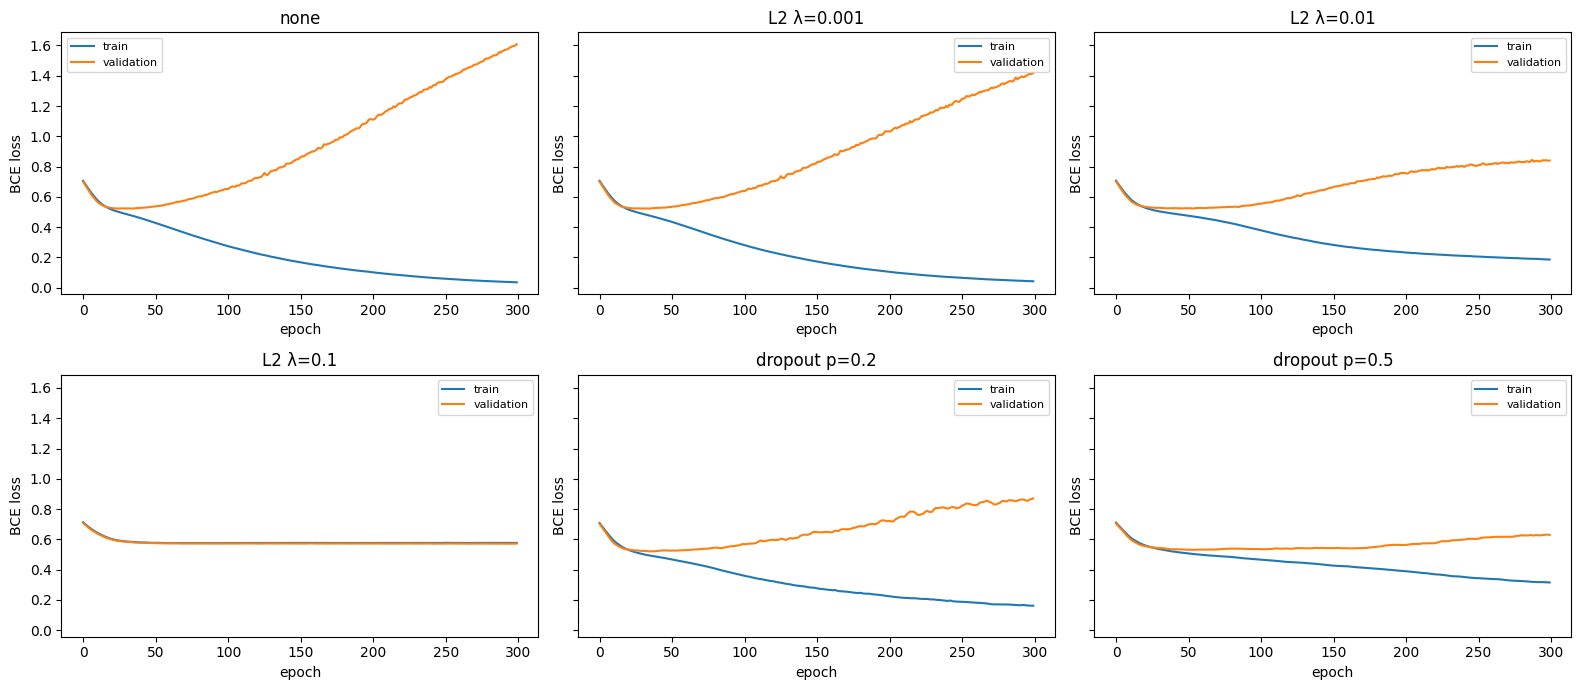

In [ ]:
# Learning curves for the first fold of each condition
conds = exp3.condition.unique()
fig, axes = plt.subplots(2, (len(conds) + 1) // 2, figsize=(16, 7), sharey=True)
for ax, cond in zip(axes.ravel(), conds):
    kw = dict(early_stopping=False)
    if cond.startswith("L2"):      kw["l2"] = float(cond.split("=")[1])
    if cond.startswith("dropout"): kw["dropout"] = float(cond.split("=")[1])
    # retrain fold 0 of seed 0 only, to plot its curves
    skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEEDS[0])
    trval_idx, te_idx = next(skf.split(df, y_all))
    tr_idx, va_idx = train_test_split(trval_idx, test_size=VAL_FRAC, stratify=y_all[trval_idx], random_state=SEEDS[0] * 100)
    Xtr, Xva = preprocess(df.iloc[tr_idx], [df.iloc[va_idx]])
    _, hist, _, _ = train_model(Xtr, y_all[tr_idx], Xva, y_all[va_idx], seed=SEEDS[0] * 100, **kw)
    ax.plot(hist["train"], label="train"); ax.plot(hist["val"], label="validation")
    ax.set(title=cond, xlabel="epoch", ylabel="BCE loss"); ax.legend(fontsize=8)
for ax in axes.ravel()[len(conds):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/exp3_curves.png", dpi=200); plt.show()

# Experiment 4
4. feature scaling: baseline standardized vs. raw inputs

raw inputs: 5 runs done


,best_epoch,val_loss,test_bce,auc,recall,accuracy
condition,,,,,,
standardized,60.000 ± 30.733,0.457 ± 0.049,0.566 ± 0.092,0.749 ± 0.081,0.438 ± 0.092,0.726 ± 0.059
raw inputs,27.200 ± 14.412,3.201 ± 2.543,2.939 ± 1.092,0.492 ± 0.099,0.342 ± 0.168,0.532 ± 0.081


,metric,comparison,mean_diff,std_diff,folds_higher,p_value
0,best_epoch,raw inputs − standardized,-32.8000,33.4171,0/5,0.0932
1,val_loss,raw inputs − standardized,2.7445,2.5827,5/5,0.0763
2,test_bce,raw inputs − standardized,2.3729,1.1425,5/5,0.0097
3,auc,raw inputs − standardized,-0.2572,0.1511,0/5,0.0190
4,recall,raw inputs − standardized,-0.0968,0.2448,1/5,0.4263


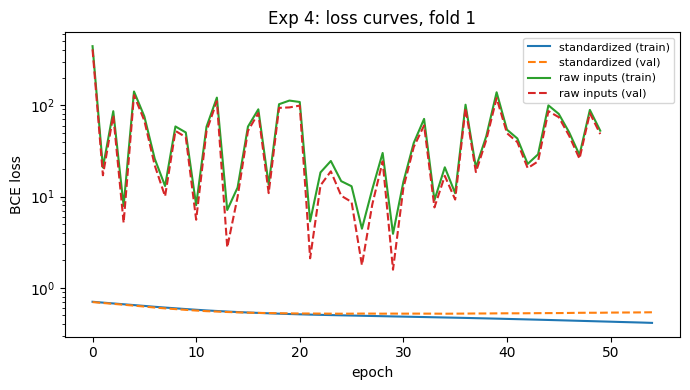

In [ ]:
res_raw, preds_raw = run_cv("raw inputs", standardize=False)
exp4 = pd.concat([res_base.assign(condition="standardized"), res_raw], ignore_index=True)

display(mean_std(exp4, ["best_epoch", "val_loss", "test_bce", "auc", "recall", "accuracy"]))
display(pd.DataFrame([paired(exp4, "standardized", "raw inputs", m)
                      for m in ["best_epoch", "val_loss", "test_bce", "auc", "recall"]]))

# Training-loss curves, first fold
fig, ax = plt.subplots(figsize=(7, 4))
for label, preds in [("standardized", preds_base), ("raw inputs", preds_raw)]:
    ax.plot(preds[0]["hist"]["train"], label=f"{label} (train)")
    ax.plot(preds[0]["hist"]["val"], ls="--", label=f"{label} (val)")
ax.set(xlabel="epoch", ylabel="BCE loss", title="Exp 4: loss curves, fold 1", yscale="log")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{RESULTS_DIR}/exp4_curves.png", dpi=200); plt.show()

# Export Results

In [ ]:
for name, table in {"exp1": exp1, "exp2": exp2, "exp3": exp3, "exp4": exp4}.items():
    table.to_csv(f"{RESULTS_DIR}/{name}_per_fold.csv", index=False)
print("Saved per-fold results and figures to", RESULTS_DIR, ":", sorted(os.listdir(RESULTS_DIR)))
# In Colab, download them with:
from google.colab import files
!zip -rq results.zip results
files.download("results.zip")

Saved per-fold results and figures to results : ['exp1_per_fold.csv', 'exp2_per_fold.csv', 'exp2_threshold.png', 'exp3_curves.png', 'exp3_per_fold.csv', 'exp4_curves.png', 'exp4_per_fold.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>